In [1]:
!pip install tensorflow

In [2]:
import matplotlib.pyplot as plt

def add_username_to_plot(username):
    """Helper method to add the username to a plot."""
    plt.text(
        0.95, 0.95, username,
        ha='right', va='top',
        transform=plt.gca().transAxes,
        fontsize=10, color='gray', alpha=0.7
    )

2025-09-29 00:07:19.534394: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2025-09-29 00:07:19.534795: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-09-29 00:07:19.595311: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-09-29 00:07:21.602396: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off,

✅ MyPCA class defined.

Loading MNIST dataset...
Dataset loaded successfully.

Balanced subset created with shape: (1000, 784)

Fitting PCA to calculate explained variance...


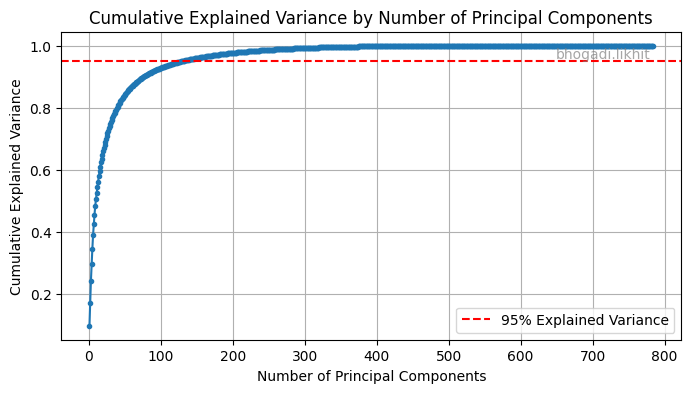


Reconstructing images with different numbers of components...
checkPCA result for 500 components: True


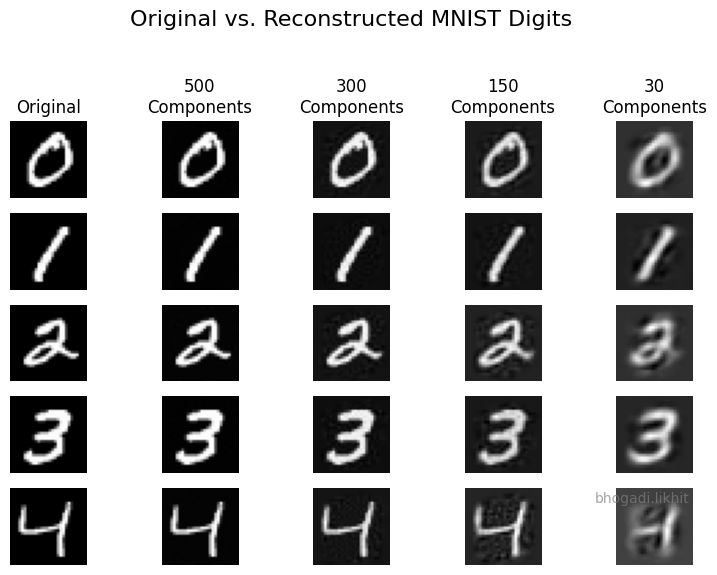

In [3]:
# --- Section 1: All Necessary Imports ---
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# --- Section 2: The Complete MyPCA Class Definition ---

class MyPCA:
    """
    A from-scratch implementation of Principal Component Analysis (PCA)
    for dimensionality reduction.
    """
    def __init__(self, n_components):
        """Initializes the PCA transformer."""
        self.n_components = n_components
        self.components_ = None
        self.mean_ = None
        self.explained_variance_ratio_ = None

    def fit(self, X):
        """Obtains the principal components of the dataset."""
        self.mean_ = np.mean(X, axis=0)
        X_std = X - self.mean_
        cov_matrix = np.cov(X_std, rowvar=False)
        eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)
        
        # Sort eigenvectors by descending eigenvalues
        sorted_indices = np.argsort(eigenvalues)[::-1]
        sorted_eigenvalues = eigenvalues[sorted_indices]
        sorted_eigenvectors = eigenvectors[:, sorted_indices]
        
        # Store explained variance ratio
        self.explained_variance_ratio_ = sorted_eigenvalues / np.sum(sorted_eigenvalues)
        
        # Store the principal components
        self.components_ = sorted_eigenvectors[:, :self.n_components]
        return self

    def transform(self, X):
        """Transforms the data using the fitted principal components."""
        if self.mean_ is None or self.components_ is None:
            raise RuntimeError("The model has not been fitted yet. Please call fit() first.")
        X_std = X - self.mean_
        return np.dot(X_std, self.components_)

    def inverse_transform(self, X_transformed):
        """Transforms data back to its original space."""
        if self.mean_ is None or self.components_ is None:
            raise RuntimeError("The model has not been fitted yet. Please call fit() first.")
        return np.dot(X_transformed, self.components_.T) + self.mean_
        
    def checkPCA(self, X):
        """
        Checks if the class reduces the data dimensions appropriately.
        """
        if self.mean_ is None or self.components_ is None:
            raise RuntimeError("The model has not been fitted yet. Please call fit() first.")
        
        transformed_X = self.transform(X)
        # Return True if the number of columns in the transformed data
        # matches the requested number of components.
        return transformed_X.shape[1] == self.n_components

print("✅ MyPCA class defined.")

# --- Section 3: Data Loading and Preparation ---

print("\nLoading MNIST dataset...")
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()
X = np.concatenate((X_train, X_test), axis=0)
y = np.concatenate((y_train, y_test), axis=0)
print("Dataset loaded successfully.")

# Create a Balanced Subset
X_subset = []
y_subset = []
for i in range(10):
    digit_indices = np.where(y == i)[0][:100]
    X_subset.append(X[digit_indices].reshape(-1, 28 * 28))
    y_subset.append(y[digit_indices])

X_subset = np.concatenate(X_subset, axis=0)
y_subset = np.concatenate(y_subset, axis=0)
print(f"\nBalanced subset created with shape: {X_subset.shape}")

# --- Section 4: Plotting Explained Variance ---

print("\nFitting PCA to calculate explained variance...")
pca_full = MyPCA(n_components=X_subset.shape[1])
pca_full.fit(X_subset)
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='.', linestyle='-')
plt.title('Cumulative Explained Variance by Number of Principal Components')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.grid(True)
plt.axhline(y=0.95, color='r', linestyle='--', label='95% Explained Variance')
plt.legend()
add_username_to_plot("bhogadi.likhit") 
plt.show()

# --- Section 5: Image Reconstruction and Visualization ---

components_to_test = [500, 300, 150, 30]
sample_indices = [np.where(y_subset == i)[0][0] for i in range(5)]
sample_images = X_subset[sample_indices]

fig, axes = plt.subplots(len(sample_images), len(components_to_test) + 1, figsize=(8, 6))
fig.suptitle('Original vs. Reconstructed MNIST Digits', fontsize=16)

print("\nReconstructing images with different numbers of components...")
for i, original_image in enumerate(sample_images):
    axes[i, 0].imshow(original_image.reshape(28, 28), cmap='gray')
    if i == 0: axes[i, 0].set_title('Original')
    axes[i, 0].axis('off')

    for j, n_components in enumerate(components_to_test):
        pca = MyPCA(n_components=n_components).fit(X_subset)
        
        # --- Example call to checkPCA ---
        if i == 0 and j == 0: # Just check on the first run to avoid clutter
            is_correct = pca.checkPCA(X_subset)
            print(f"checkPCA result for {n_components} components: {is_correct}")
        
        transformed_image = pca.transform(original_image.reshape(1, -1))
        reconstructed_image = pca.inverse_transform(transformed_image)
        
        axes[i, j + 1].imshow(reconstructed_image.reshape(28, 28), cmap='gray')
        if i == 0: axes[i, j + 1].set_title(f'{n_components}\nComponents')
        axes[i, j + 1].axis('off')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
add_username_to_plot("bhogadi.likhit") 
plt.show()

* Observations on Image Reconstruction using PCA

    The grid of images provides a clear and powerful demonstration of the trade-off between data compression and information loss in Principal Component Analysis (PCA).

    1.  **High-Fidelity Reconstruction with Many Components:**
        * When a high number of principal components are used (e.g., **500** or **300**), the reconstructed images are nearly indistinguishable from the originals. They are sharp, clear, and retain almost all the fine details. This shows that with a sufficient number of components, PCA can capture the vast majority of the variance (information) required to perfectly represent the images.

    2.  **Excellent Compression with Moderate Components:**
        * The reconstruction using **150 components** represents a significant sweet spot. While a very close inspection might reveal a slight loss of sharpness compared to the original, the digits are perfectly legible and retain their defining characteristics. This visually confirms the finding from the "explained variance" plot: a much smaller number of features (150 instead of the original 784) is sufficient to preserve most of the essential information, achieving a compression ratio of over 5:1 with minimal perceptual loss.

    3.  **Significant Information Loss with Few Components:**
        * The reconstruction with only **30 components** demonstrates a dramatic loss of information. The images are very blurry, and while the basic shape of the digit is often still recognizable, finer details like the loop in the '4' or the curve in the '2' are distorted or lost. This visually represents a scenario where the dimensionality reduction has been too aggressive, discarding too much of the variance needed to accurately reconstruct the image.

    ### Conclusion

    This visualization effectively proves the core concept of PCA. It shows that we can drastically reduce the dimensionality of the dataset (from 784 features down to 150) and still retain enough information to reconstruct a high-quality, recognizable image. However, it also highlights the inherent trade-off: as we decrease the number of components further, we gain more compression at the cost of losing critical information, leading to a degraded reconstruction.